# ETT: 4系列のTCN予測

ETTh1・ETTh2・ETTm1・ETTm2を順番に処理し、各系列についてTCNの負荷なし・負荷ありモデルを比較する。直前OTを基準とし、過去24時間のOT・暦情報・負荷から次の観測時刻のOT変化を予測する。

- ETThは1時間先、ETTmは15分先を予測する。対象時刻のOTや負荷は入力せず、直前時刻までに観測済みの情報のみを使用する。
- 各系列を時系列順に70%学習、10%検証、20%テストに分ける。標準化と月別・時刻別パターンは各系列の学習期間のみから計算する。
- TCNは32フィルター、カーネルサイズ2、拡張率1・2・4・8・16・32の因果畳み込みを使用する。学習率0.001、MSE、検証損失による早期停止を使用し、予測変化量に掛ける係数は0.5に固定する。
- 直前OTと時刻別パターンのベースラインも同じ予測対象時刻で評価する。1回の分割での比較は探索的であり、季節による偏りや汎化性能を確定するものではない。
- データセットごとの評価表・予測値・図はDriveの `assignment-main/model_output_tcn_all/<DATASET>` に保存し、全系列の評価表も `model_output_tcn_all` に保存する。データセットごとにZIPを作成する。同名の成果物は再実行時に上書きされる。

## Colabでの準備

コピー元の古い実行結果が表示されている場合があるため、先頭から再実行する。最初のコードセルで `keras-tcn` をインストールし、Google Driveをマウントする。EDAと同じ `/content/drive/Othercomputers/マイ Mac/assignment-main/data` に4系列のCSVを配置する。学習は全8モデルのため時間がかかる。

In [1]:
%pip install -q keras-tcn

In [2]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("/content/drive/Othercomputers/マイ Mac/assignment-main/data")
SEED = 42
EPOCHS = 30
BATCH_SIZE = 128
PATIENCE = 5

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

drive.mount("/content/drive")
print(f"TensorFlow: {tf.__version__}, data directory: {DATA_DIR}")

Mounted at /content/drive
TensorFlow: 2.21.0, data directory: /content/drive/Othercomputers/マイ Mac/assignment-main/data



=== ETTh1: 間隔 0 days 01:00:00, 履歴 24ステップ ===
train: 12,170件, 予測対象 2016-07-02 00:00:00 〜 2017-11-21 01:00:00
validation: 1,742件, 予測対象 2017-11-21 02:00:00 〜 2018-02-01 15:00:00
test: 3,484件, 予測対象 2018-02-01 16:00:00 〜 2018-06-26 19:00:00

--- ETTh1: TCN: OT + calendar ---
Epoch 1/30
96/96 - 30s - 316ms/step - loss: 0.0140 - val_loss: 0.0044
Epoch 2/30
96/96 - 10s - 103ms/step - loss: 0.0138 - val_loss: 0.0044
Epoch 3/30
96/96 - 14s - 143ms/step - loss: 0.0136 - val_loss: 0.0044
Epoch 4/30
96/96 - 6s - 58ms/step - loss: 0.0135 - val_loss: 0.0045
Epoch 5/30
96/96 - 8s - 85ms/step - loss: 0.0134 - val_loss: 0.0046
Epoch 6/30
96/96 - 7s - 73ms/step - loss: 0.0133 - val_loss: 0.0047
Epoch 7/30
96/96 - 12s - 120ms/step - loss: 0.0131 - val_loss: 0.0054

--- ETTh1: TCN: OT + calendar + load ---
Epoch 1/30
96/96 - 14s - 143ms/step - loss: 0.0141 - val_loss: 0.0048
Epoch 2/30
96/96 - 6s - 59ms/step - loss: 0.0138 - val_loss: 0.0044
Epoch 3/30
96/96 - 8s - 86ms/step - loss: 0.0136 - val_loss: 0.0

,dataset,split,model,count,MAE,RMSE
0,ETTh1,validation,Persistence,1742,0.4034,0.5653
1,ETTh1,validation,Time pattern,1742,0.4243,0.5706
2,ETTh1,validation,TCN: OT + calendar,1742,0.3987,0.5565
3,ETTh1,validation,TCN: OT + calendar + load,1742,0.3946,0.5512
4,ETTh1,test,Persistence,3484,0.4481,0.6542
5,ETTh1,test,Time pattern,3484,0.4349,0.6352
6,ETTh1,test,TCN: OT + calendar,3484,0.4318,0.6352
7,ETTh1,test,TCN: OT + calendar + load,3484,0.4191,0.6211


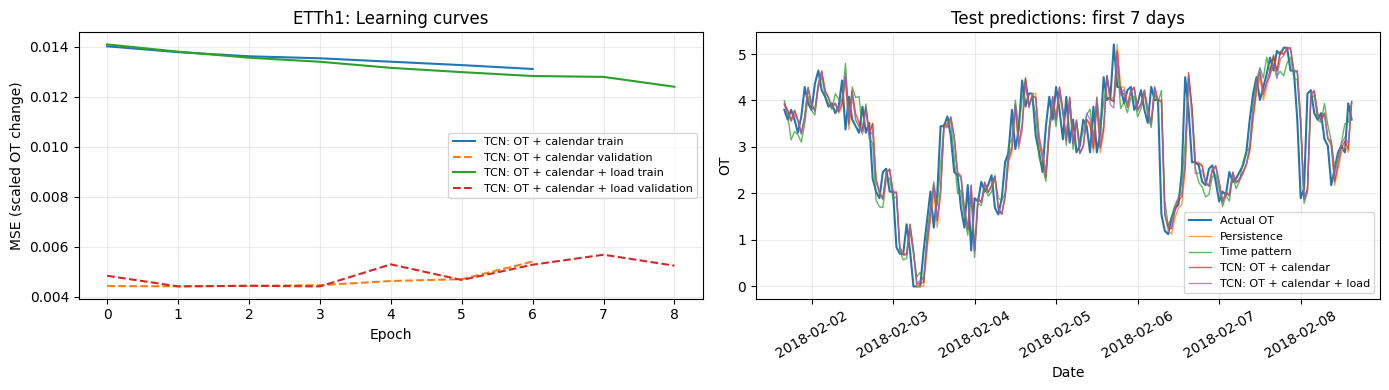

保存先: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output_tcn_all/ETTh1 ZIP: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTh1_tcn_all_model_outputs.zip

=== ETTh2: 間隔 0 days 01:00:00, 履歴 24ステップ ===
train: 12,170件, 予測対象 2016-07-02 00:00:00 〜 2017-11-21 01:00:00
validation: 1,742件, 予測対象 2017-11-21 02:00:00 〜 2018-02-01 15:00:00
test: 3,484件, 予測対象 2018-02-01 16:00:00 〜 2018-06-26 19:00:00

--- ETTh2: TCN: OT + calendar ---
Epoch 1/30
96/96 - 13s - 139ms/step - loss: 0.0074 - val_loss: 0.0041
Epoch 2/30
96/96 - 6s - 62ms/step - loss: 0.0061 - val_loss: 0.0047
Epoch 3/30
96/96 - 8s - 84ms/step - loss: 0.0057 - val_loss: 0.0032
Epoch 4/30
96/96 - 6s - 58ms/step - loss: 0.0053 - val_loss: 0.0034
Epoch 5/30
96/96 - 8s - 87ms/step - loss: 0.0051 - val_loss: 0.0025
Epoch 6/30
96/96 - 6s - 58ms/step - loss: 0.0050 - val_loss: 0.0025
Epoch 7/30
96/96 - 12s - 126ms/step - loss: 0.0048 - val_loss: 0.0027
Epoch 8/30
96/96 - 6s - 58ms/step - loss: 0.0047 - val_loss: 0.0023
Epoch

,dataset,split,model,count,MAE,RMSE
0,ETTh2,validation,Persistence,1742,0.7803,1.1555
1,ETTh2,validation,Time pattern,1742,0.5768,0.7609
2,ETTh2,validation,TCN: OT + calendar,1742,0.5162,0.7374
3,ETTh2,validation,TCN: OT + calendar + load,1742,0.5507,0.7707
4,ETTh2,test,Persistence,3484,0.9716,1.3312
5,ETTh2,test,Time pattern,3484,0.6378,0.8726
6,ETTh2,test,TCN: OT + calendar,3484,0.6666,0.9439
7,ETTh2,test,TCN: OT + calendar + load,3484,0.6826,0.9446


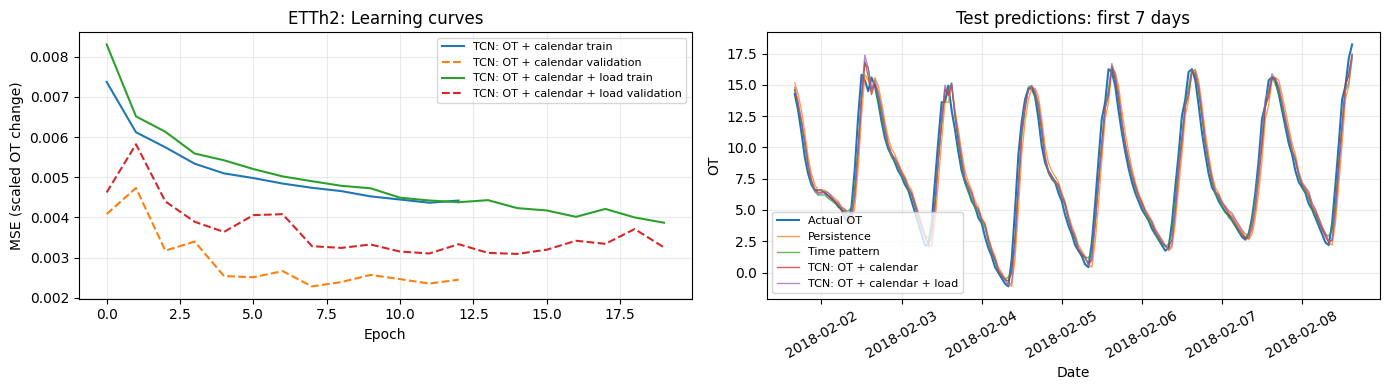

保存先: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output_tcn_all/ETTh2 ZIP: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTh2_tcn_all_model_outputs.zip

=== ETTm1: 間隔 0 days 00:15:00, 履歴 96ステップ ===
train: 48,680件, 予測対象 2016-07-02 00:00:00 〜 2017-11-21 01:45:00
validation: 6,968件, 予測対象 2017-11-21 02:00:00 〜 2018-02-01 15:45:00
test: 13,936件, 予測対象 2018-02-01 16:00:00 〜 2018-06-26 19:45:00

--- ETTm1: TCN: OT + calendar ---
Epoch 1/30
381/381 - 68s - 179ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 2/30
381/381 - 81s - 212ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 3/30
381/381 - 82s - 216ms/step - loss: 0.0034 - val_loss: 0.0013
Epoch 4/30
381/381 - 82s - 215ms/step - loss: 0.0034 - val_loss: 0.0013
Epoch 5/30
381/381 - 82s - 214ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 6/30
381/381 - 82s - 216ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 7/30
381/381 - 84s - 220ms/step - loss: 0.0033 - val_loss: 0.0012
Epoch 8/30
381/381 - 81s - 214ms/step - loss: 0.

,dataset,split,model,count,MAE,RMSE
0,ETTm1,validation,Persistence,6968,0.2073,0.2918
1,ETTm1,validation,Time pattern,6968,0.2131,0.2919
2,ETTm1,validation,TCN: OT + calendar,6968,0.2090,0.2899
3,ETTm1,validation,TCN: OT + calendar + load,6968,0.2079,0.2889
4,ETTm1,test,Persistence,13936,0.2141,0.3225
5,ETTm1,test,Time pattern,13936,0.2154,0.3207
6,ETTm1,test,TCN: OT + calendar,13936,0.2153,0.3215
7,ETTm1,test,TCN: OT + calendar + load,13936,0.2131,0.3192


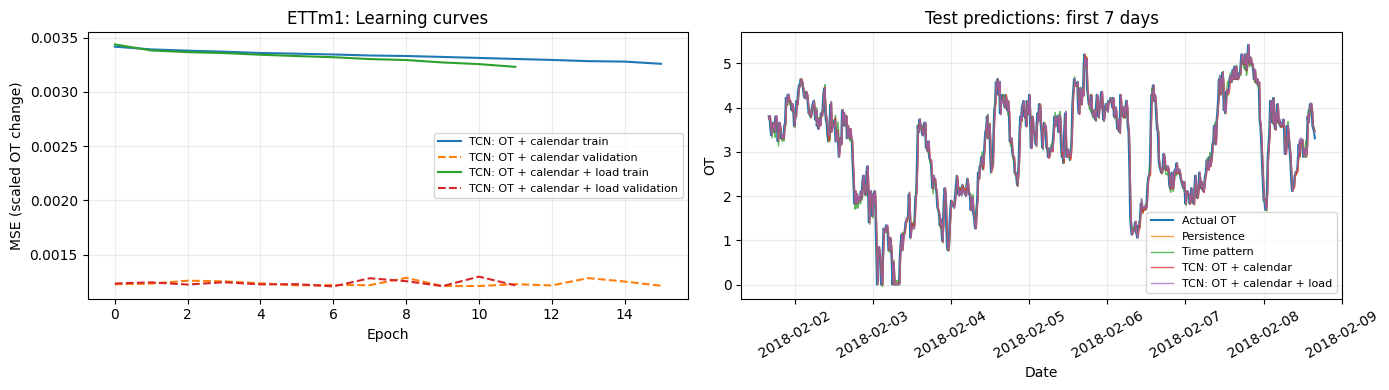

保存先: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output_tcn_all/ETTm1 ZIP: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTm1_tcn_all_model_outputs.zip

=== ETTm2: 間隔 0 days 00:15:00, 履歴 96ステップ ===
train: 48,680件, 予測対象 2016-07-02 00:00:00 〜 2017-11-21 01:45:00
validation: 6,968件, 予測対象 2017-11-21 02:00:00 〜 2018-02-01 15:45:00
test: 13,936件, 予測対象 2018-02-01 16:00:00 〜 2018-06-26 19:45:00

--- ETTm2: TCN: OT + calendar ---
Epoch 1/30
381/381 - 71s - 187ms/step - loss: 0.0010 - val_loss: 3.1364e-04
Epoch 2/30
381/381 - 64s - 168ms/step - loss: 9.2074e-04 - val_loss: 3.0655e-04
Epoch 3/30
381/381 - 82s - 214ms/step - loss: 8.9300e-04 - val_loss: 2.9860e-04
Epoch 4/30
381/381 - 64s - 167ms/step - loss: 8.7394e-04 - val_loss: 2.7671e-04
Epoch 5/30
381/381 - 82s - 216ms/step - loss: 8.6421e-04 - val_loss: 2.7026e-04
Epoch 6/30
381/381 - 64s - 167ms/step - loss: 8.5814e-04 - val_loss: 2.7597e-04
Epoch 7/30
381/381 - 82s - 214ms/step - loss: 8.3656e-04 - val_loss: 3.5638e

,dataset,split,model,count,MAE,RMSE
0,ETTm2,validation,Persistence,6968,0.1970,0.3185
1,ETTm2,validation,Time pattern,6968,0.1824,0.2310
2,ETTm2,validation,TCN: OT + calendar,6968,0.1510,0.2127
3,ETTm2,validation,TCN: OT + calendar + load,6968,0.1589,0.2188
4,ETTm2,test,Persistence,13936,0.2467,0.3692
5,ETTm2,test,Time pattern,13936,0.2016,0.2689
6,ETTm2,test,TCN: OT + calendar,13936,0.1868,0.2624
7,ETTm2,test,TCN: OT + calendar + load,13936,0.1945,0.2719


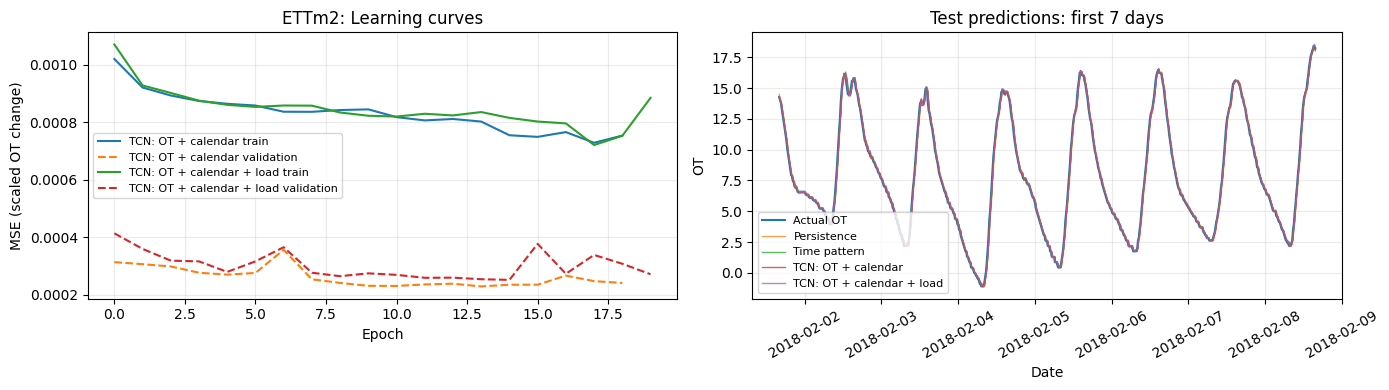

保存先: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output_tcn_all/ETTm2 ZIP: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTm2_tcn_all_model_outputs.zip
全系列の評価


,dataset,split,model,count,MAE,RMSE
0,ETTh1,validation,Persistence,1742,0.4034,0.5653
1,ETTh1,validation,Time pattern,1742,0.4243,0.5706
2,ETTh1,validation,TCN: OT + calendar,1742,0.3987,0.5565
3,ETTh1,validation,TCN: OT + calendar + load,1742,0.3946,0.5512
4,ETTh1,test,Persistence,3484,0.4481,0.6542
5,ETTh1,test,Time pattern,3484,0.4349,0.6352
6,ETTh1,test,TCN: OT + calendar,3484,0.4318,0.6352
7,ETTh1,test,TCN: OT + calendar + load,3484,0.4191,0.6211
8,ETTh2,validation,Persistence,1742,0.7803,1.1555
9,ETTh2,validation,Time pattern,1742,0.5768,0.7609


In [3]:
from tcn import TCN
import shutil

DATASETS = ["ETTh1", "ETTh2", "ETTm1", "ETTm2"]
OUTPUT_ROOT = DATA_DIR.parent / "model_output_tcn_all"
CALENDAR_PATTERN_WEIGHT = 1.0
PATTERN_PRIOR_COUNT = 20
TCN_FILTERS = 32
TCN_DILATIONS = [1, 2, 4, 8, 16, 32]
LEARNING_RATE = 0.001
CORRECTION_WEIGHT = 0.5


def run_dataset(dataset_name):
    data_path = DATA_DIR / f"{dataset_name}.csv"
    if not data_path.is_file():
        raise FileNotFoundError(f"CSVが見つかりません: {data_path}")
    load_columns = ["HUFL", "HULL", "LUFL", "LULL"]
    sensor_columns = ["OT"] + load_columns
    frame = pd.read_csv(data_path, parse_dates=["date"])
    missing_columns = set(["date"] + sensor_columns) - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{dataset_name}: 必要な列がありません: {missing_columns}")
    if frame[["date"] + sensor_columns].isna().any().any():
        raise ValueError(f"{dataset_name}: 日時またはセンサ値に欠損があります。")
    if not np.isfinite(frame[sensor_columns].to_numpy(dtype=float)).all():
        raise ValueError(f"{dataset_name}: センサ値に無限大があります。")
    interval = pd.Timedelta(hours=1) if dataset_name.startswith("ETTh") else pd.Timedelta(minutes=15)
    if not frame["date"].diff().iloc[1:].eq(interval).all():
        raise ValueError(f"{dataset_name}: 日時が重複、不整列、または{interval}間隔でない箇所があります。")

    lookback = int(pd.Timedelta(days=1) / interval)
    train_end = int(len(frame) * 0.7)
    validation_end = int(len(frame) * 0.8)
    if train_end <= lookback or validation_end <= train_end or validation_end >= len(frame):
        raise ValueError(f"{dataset_name}: 指定した履歴長と分割に対してデータが不足しています。")
    timestamps = frame["date"]
    ot_values = frame["OT"].to_numpy(dtype=np.float32)
    train_indices = np.arange(lookback, train_end, dtype=np.int32)
    validation_indices = np.arange(train_end, validation_end, dtype=np.int32)
    test_indices = np.arange(validation_end, len(frame), dtype=np.int32)
    print(f"\n=== {dataset_name}: 間隔 {interval}, 履歴 {lookback}ステップ ===")
    for label, indices in [("train", train_indices), ("validation", validation_indices), ("test", test_indices)]:
        print(f"{label}: {len(indices):,}件, 予測対象 {timestamps.iloc[indices[0]]} 〜 {timestamps.iloc[indices[-1]]}")

    scaler = StandardScaler()
    scaler.fit(frame.iloc[:train_end][sensor_columns])
    scaled_sensors = scaler.transform(frame[sensor_columns]).astype(np.float32)
    ot_scale = float(scaler.scale_[0])
    residuals = np.zeros(len(frame), dtype=np.float32)
    residuals[1:] = (ot_values[1:] - ot_values[:-1]) / ot_scale
    day_fraction = (timestamps.dt.hour * 60 + timestamps.dt.minute) / (24 * 60)
    week_fraction = (timestamps.dt.dayofweek + day_fraction) / 7
    year_fraction = (timestamps.dt.dayofyear - 1 + day_fraction) / np.where(timestamps.dt.is_leap_year, 366, 365)
    calendar = np.column_stack([
        np.sin(2 * np.pi * day_fraction), np.cos(2 * np.pi * day_fraction),
        np.sin(2 * np.pi * week_fraction), np.cos(2 * np.pi * week_fraction),
        np.sin(2 * np.pi * year_fraction), np.cos(2 * np.pi * year_fraction),
    ]).astype(np.float32)
    time_slots = (day_fraction * lookback).astype(int)
    training_changes = pd.DataFrame({
        "month": timestamps.iloc[train_indices].dt.month.to_numpy(),
        "time_slot": time_slots.iloc[train_indices].to_numpy(),
        "change": residuals[train_indices],
    })
    overall_change = float(training_changes["change"].mean())

    def calculate_pattern(group_column):
        grouped = training_changes.groupby(group_column)["change"].agg(["mean", "count"])
        grouped["pattern"] = (grouped["mean"] * grouped["count"] + overall_change * PATTERN_PRIOR_COUNT) / (grouped["count"] + PATTERN_PRIOR_COUNT)
        return grouped

    seasonal_pattern = calculate_pattern("month")
    time_pattern = calculate_pattern("time_slot")
    seasonal_values = timestamps.dt.month.map(seasonal_pattern["pattern"]).fillna(overall_change).to_numpy()
    time_values = time_slots.map(time_pattern["pattern"]).fillna(overall_change).to_numpy(dtype=np.float32)
    next_patterns = np.zeros((len(frame), 2), dtype=np.float32)
    next_patterns[:-1, 0] = seasonal_values[1:]
    next_patterns[:-1, 1] = time_values[1:]
    next_patterns *= CALENDAR_PATTERN_WEIGHT
    feature_sets = {
        "TCN: OT + calendar": np.column_stack([scaled_sensors[:, 0], calendar, next_patterns]).astype(np.float32),
        "TCN: OT + calendar + load": np.column_stack([scaled_sensors, calendar, next_patterns]).astype(np.float32),
    }

    def make_dataset(feature_array, indices, training=False):
        feature_tensor = tf.constant(feature_array, dtype=tf.float32)
        target_tensor = tf.constant(residuals, dtype=tf.float32)
        offsets = tf.range(-lookback, 0, dtype=tf.int32)
        dataset = tf.data.Dataset.from_tensor_slices(indices)
        if training:
            dataset = dataset.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
        dataset = dataset.map(
            lambda index: (tf.gather(feature_tensor, index + offsets), tf.gather(target_tensor, index)),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
        return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    histories = {}
    corrections = {"validation": {}, "test": {}}
    for name, feature_array in feature_sets.items():
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(lookback, feature_array.shape[1])),
            TCN(nb_filters=TCN_FILTERS, kernel_size=2, dilations=TCN_DILATIONS,
                padding="causal", return_sequences=False),
            tf.keras.layers.Dense(16, activation="relu"),
            tf.keras.layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros"),
        ])
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss="mse")
        early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        print(f"\n--- {dataset_name}: {name} ---")
        history = model.fit(
            make_dataset(feature_array, train_indices, training=True),
            validation_data=make_dataset(feature_array, validation_indices),
            epochs=EPOCHS, callbacks=[early_stopping], verbose=2,
        )
        histories[name] = history.history
        for split_name, indices in [("validation", validation_indices), ("test", test_indices)]:
            corrections[split_name][name] = model.predict(make_dataset(feature_array, indices), verbose=0).reshape(-1) * ot_scale

    prediction_frames = []
    for split_name, indices in [("validation", validation_indices), ("test", test_indices)]:
        previous_ot = ot_values[indices - 1]
        predictions = {"Persistence": previous_ot, "Time pattern": previous_ot + time_values[indices] * ot_scale}
        for name, correction in corrections[split_name].items():
            predictions[name] = previous_ot + CORRECTION_WEIGHT * correction
        prediction_frames.append(pd.DataFrame({
            "split": split_name, "date": timestamps.iloc[indices].to_numpy(),
            "actual_OT": ot_values[indices], **predictions,
        }))
    all_predictions = pd.concat(prediction_frames, ignore_index=True)
    prediction_columns = ["Persistence", "Time pattern", *feature_sets]
    results = []
    for split_name in ["validation", "test"]:
        split_frame = all_predictions[all_predictions["split"] == split_name]
        for name in prediction_columns:
            results.append({
                "dataset": dataset_name, "split": split_name, "model": name, "count": len(split_frame),
                "MAE": mean_absolute_error(split_frame["actual_OT"], split_frame[name]),
                "RMSE": np.sqrt(mean_squared_error(split_frame["actual_OT"], split_frame[name])),
            })
    metrics = pd.DataFrame(results)
    display(metrics.round(4))
    test_predictions = all_predictions[all_predictions["split"] == "test"].copy()
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for name, history in histories.items():
        axes[0].plot(history["loss"], label=f"{name} train")
        axes[0].plot(history["val_loss"], linestyle="--", label=f"{name} validation")
    axes[0].set(title=f"{dataset_name}: Learning curves", xlabel="Epoch", ylabel="MSE (scaled OT change)")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.25)
    plot_data = test_predictions.iloc[:min(len(test_predictions), lookback * 7)]
    axes[1].plot(plot_data["date"], plot_data["actual_OT"], label="Actual OT", linewidth=1.5)
    for name in prediction_columns:
        axes[1].plot(plot_data["date"], plot_data[name], label=name, alpha=0.75, linewidth=1)
    axes[1].set(title="Test predictions: first 7 days", xlabel="Date", ylabel="OT")
    axes[1].tick_params(axis="x", rotation=30)
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.25)
    fig.tight_layout()

    output_dir = OUTPUT_ROOT / dataset_name
    table_dir = output_dir / "tables"
    figure_dir = output_dir / "figures"
    table_dir.mkdir(parents=True, exist_ok=True)
    figure_dir.mkdir(parents=True, exist_ok=True)
    seasonal_pattern.reset_index().to_csv(table_dir / f"{dataset_name}_monthly_change_pattern.csv", index=False)
    time_pattern.reset_index().to_csv(table_dir / f"{dataset_name}_time_change_pattern.csv", index=False)
    metrics.to_csv(table_dir / f"{dataset_name}_metrics.csv", index=False)
    test_predictions.to_csv(table_dir / f"{dataset_name}_test_predictions.csv", index=False)
    fig.savefig(figure_dir / f"{dataset_name}_learning_curves_and_predictions.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    zip_path = shutil.make_archive(str(DATA_DIR.parent / f"{dataset_name}_tcn_all_model_outputs"), "zip", root_dir=output_dir)
    print("保存先:", output_dir, "ZIP:", zip_path)
    return metrics


missing_files = [str(DATA_DIR / f"{name}.csv") for name in DATASETS if not (DATA_DIR / f"{name}.csv").is_file()]
if missing_files:
    raise FileNotFoundError(f"対象CSVがありません: {missing_files}")
all_metrics = pd.concat([run_dataset(name) for name in DATASETS], ignore_index=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
all_metrics.to_csv(OUTPUT_ROOT / "all_datasets_metrics.csv", index=False)
print("全系列の評価")
display(all_metrics.round(4))